# UKFによる状態推定


1. UKFによる状態推定
2. UKFによる外乱推定
3. UKFによるパラメータ推定
4. UKFによる外乱・パラメータの同時推定

## 運動方程式

以下の剛性が非線形なバネ-マス-ダンパ系の運動方程式とする。

$$
m \ddot{x} +  c \dot{x} + k x |x| =  u + d
$$

- $m$ : 慣性 [$kg$]
- $c$ : 粘性 [$Ns/m$]
- $k$ : 剛性 [$N/m^2$]
- $u$ : 既知の制御入力 [$N$]
- $d$ : 未知外乱 [$N$]

## 状態方程式

状態ベクトル$X$とする。

$$
X = \begin{bmatrix} x \\ v \end{bmatrix}
$$

これより、連続時間の状態方程式は以下となる。

$$
\begin{bmatrix}
\dot{x} \\ \dot{v}
\end{bmatrix} =
\begin{bmatrix}
v \\
\frac{1}{m}\left( u - c v - k x|x| + d \right)
\end{bmatrix}
$$

前進Euler法による離散時間モデルは、以下となる。
$$
\begin{array}{c}
X_{n+1} = f(X_n ,u_n) + w_n \\ \downarrow \\
\begin{bmatrix}
x_{n+1} \\ v_{n+1}
\end{bmatrix} =
\begin{bmatrix}
x_{n} + \Delta t v_n \\
v_n + \frac{\Delta t}{m}\left( u_n - c v_n - k x_n|x_n| + d_n \right)
\end{bmatrix} + w_n
\end{array}
$$

$w_n$ は $\mathcal{N}(0, Q_n)$ に従うプロセスノイズである。


## 観測方程式

状態推定を行うため、観測値は、位置または速度で行い。これは、観測値を位置と速度として比較した場合、結果に差ができるかを確認するためである。

$$
\begin{array}{c}
z_{n+1} = h(x_{n+1}) + r_{n+1} \\ \downarrow \\
z_{n+1} = x_{n+1} + r_{n+1} \quad \text{or} \quad z_{n+1} = v_{n+1} + r_{n+1}
\end{array}
$$

$r_{n+1}$は $\mathcal{N}(0, R_{n+1})$ に従う観測ノイズである。


## 1. 状態推定

状態推定では未知外乱は$d=0$として行う。

状態数は$n=2$である。

シグマポイントに関するパラメータは$\alpha=1, \kappa = 0, \beta = 2$とする。

$$
\lambda = \alpha^2(n+\kappa) -n
$$

平均計算用重み

$$
W_0^{(m)} = \frac{\lambda}{n+\lambda} , \quad W_i^{(m)} = \frac{1}{2(n+\lambda)}, \space i=1,...,4
$$

共分散計算用重み

$$
W_0^{(c)} = W_0^{(m)} + (1 - \alpha^2 + \beta) , \quad W_i^{(c)} = W_i^{(m)}, \space i=1,...,4
$$

以上を用いて、1ループの処理は以下となる。

### 1.1 UKF１ループの処理

#### 1.1.1 シグマポイントの計算

時刻$k$時の事後推定の推定状態を$\hat{x}_{k|k} \in \mathcal{R}^{2 \times 1}$、誤差共分散行列を$P_{k|k} \in \mathcal{R}^{2 \times 2}$とし、シグマポイント $\chi_{k|k} \in \mathcal{R}^{2 \times 1}$ を計算する。

$$
\begin{aligned}
\chi_{k|k}^{(0)} &= \hat{x}_{k|k} \\
\chi_{k|k}^{(i)} &= \hat{x}_{k|k} + \sqrt{n+\lambda} \left(\sqrt{P_{{k|k}}}\right)_i, \space i = 1,2 \\
\chi_{k|k}^{(n+i)} &= \hat{x}_{k|k} - \sqrt{n+\lambda} \left(\sqrt{P_{{k|k}}}\right)_i, \space i = 1,2 \\
\end{aligned}
$$

#### 1.1.2 次状態の予測値(事前推定値)を計算

シグマポイント$\chi_{k|k}$を状態方程式を通過させ、次状態のシグマポイント$\chi_{k+1|k}$を求める。

$$
\chi_{k+1|k}^{(i)} = f(\chi_{k|k}^{(i)}, u_k), \space i=0,..,4
$$

$\chi_{k+1|k}$の平均値を計算し、次状態の予測値を求める。

$$
\hat{x}_{k+1|k} = \sum_{i=0}^{4}W_i^{(m)}\chi_{k+1|k}^{(i)}
$$

次状態の予測誤差共分散を求める。

$$
P_{k+1|k} = \sum_{i=0}^{4} W_i^{(c)} \left( \chi_{k+1|k}^{(i)} - \hat{x}_{k+1|k} \right) \left( \chi_{k+1|k}^{(i)} - \hat{x}_{k+1|k} \right)^T + Q_k
$$

#### 1.1.3 事前推定値からシグマポイントを計算

事前推定値の$\hat{x}_{k+1|k}$と$P_{k+1|k}$からシグマポイント$\psi_{k+1|k}  \in \mathcal{R}^{2 \times 1}$を求める。

$$
\begin{aligned}
\psi_{k+1|k}^{(0)} &= \hat{x}_{k+1|k} \\
\psi_{k+1|k}^{(i)} &= \hat{x}_{k+1|k} + \sqrt{n+\lambda} \left(\sqrt{P_{{k+1|k}}}\right)_i, \space i = 1,2 \\
\psi_{k+1|k}^{(n+i)} &= \hat{x}_{k+1|k} - \sqrt{n+\lambda} \left(\sqrt{P_{{k+1|k}}}\right)_i, \space i = 1,2 \\
\end{aligned}
$$

#### 1.1.4 観測値の予測値を計算

シグマポイント$\psi_{k+1|k}$を観測方程式を通過させ、観測空間でのシグマポイント$Z_{k+1} \in \mathcal{R}^{1 \times 1}$を求める。

$$
Z_{k+1}^{(i)} = h(\psi_{k+1|k}^{(i)}) , \space i=0,...,4
$$

$Z_{k+1}$の平均値を計算し、観測値の予測値$\hat{z}_{k+1|k}  \in \mathcal{R}^{1 \times 1}$を求める。

$$
\hat{z}_{k+1|k} = \sum_0^{4} W_i^{(m)} Z_{k+1}^{(i)}
$$

観測値の予測誤差共分散$S_{k+1} \in \mathcal{R}^{1 \times 1}$を求める。

$$
S_{k+1} = \sum_{i=0}^{4} W_i^{(c)} \left( Z_{k+1}^{(i)} - \hat{z}_{k+1|k} \right) \left( Z_{k+1}^{(i)} - \hat{z}_{k+1|k} \right)^T + R_{k+1}
$$

#### 1.1.5 交差共分散を計算

シグマポイント$\psi_{k+1|k}, Z_{k+1}$から交差共分散$P_{xz} \in \mathcal{R}^{2 \times 1}$ を計算する。

$$
P_{xz} = \sum_{i=0}^4 W_i^{(c)} \left( \psi_{k+1|k}^{(i)} - \hat{x}_{k+1|k} \right) \left( Z_{k+1}^{(i)} - \hat{z}_{k+1|k} \right)^T
$$

#### 1.1.6 Kalma Gainを計算

観測値の予測誤差共分散$S_{k+1}$ と交差共分散 $P_{xz}$からKalman Gain $K_{k+1} \in \mathcal{R}^{2 \times 1}$ を計算する。

$$
K_{k+1} = P_{xz}S_{k+1}^{-1}
$$

#### 1.1.7 状態の更新

システムの測定値$z_{k+1} \in \mathcal{R}^{1 \times 1}$ と観測値の予測値 $\hat{z}_{k+1|k}$ からinnovation $\tilde{z}_{k+1} \in \mathcal{R}^{1 \times 1}$ を求める。

$$
\tilde{z}_{k+1} = z_{k+1} - \hat{z}_{k+1|k}
$$

時刻$k+1$時の事後推定の状態$\hat{x}_{k+1|k+1} \in \mathcal{R}^{2 \times 1}$ を事前推定の状態$\hat{x}_{k+1|k}$とKalman Gain $K_{k+1}$により以下で更新する。

$$
\hat{x}_{k+1|k+1} = \hat{x}_{k+1|k} + K_{k+1} \tilde{z}_{k+1}
$$

#### 1.1.8 誤差共分散の更新

時刻$k+1$時の事後推定の誤差共分散の$P_{k+1|k+1} \in \mathcal{R}^{2 \times 2}$ を事前状態の誤差共分散$P_{k+1|k}$、Kalman Gain$K_{k+1}$と観測値の予測誤差共分散$S_{k+1}$を持ちて以下で更新する。

$$
P_{k+1|k+1} = P_{k+1|k} - K_{k+1} S_{k+1} K_{k+1}^T
$$

これで時刻$k+1$での事後推定値が求まる。以降は1.1に戻り、各時刻での推定を行う。

### 1.2 Python Code


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import List, Optional

In [6]:
@dataclass
class Parameters:

    dt:float  = 1e-3 # Simulation Step

    m:float = 10 # 慣性 [kg]
    c:float = 0.1 # 粘性 [N s/m]
    k:float = 1.4 # 剛性 [N/m^2]

    # 状態数
    nx : int = 2

    # 観測数
    nz : int = 1

    # 誤差共分散行列の初期値
    P_init : np.ndarray = field(
        default_factory=lambda: np.diag([1e2, 1e2]), compare=False
    )

    # プロセスノイズの分散Q
    Q: np.ndarray = field(
        default_factory=lambda: np.diag([1e-3, 1e-3]), compare=False
    )

    # 観測ノイズの分散R
    R: np.ndarray = field(
        default_factory=lambda: np.array([[1e-2]]), compare=False
    )

    alpha:float  = 1.0
    beta:float = 2.0
    kappa:float = 0.0

def fake_real_system(X_n:np.ndarray, u_n:float, d_n:float , params:Parameters):
    x_n, v_n = X_n
    x_next = x_n + params.dt * v_n
    v_next = v_n + params.dt/params.m*(u_n - params.c * v_n - params.k * x_n * np.abs(x_n) + d_n)
    return np.array([x_next,v_next])

def fake_mesurement_value(X_n:np.ndarray, mesure_speed:bool=False):
    x_n, v_n = X_n
    if mesure_speed:
        return np.array([v_n])
    else:
        return np.array([x_n])

def fake_process_noize(params:Parameters):
    return np.random.multivariate_normal(mean=np.zeros(params.nx), cov=params.Q)

def fake_mesurement_noiz(params:Parameters):
    return np.random.normal(loc=0, scale=np.sqrt(params.R[0,0]), size=params.nz)

def generate_sigma_points(x_mean:np.ndarray, P:np.ndarray, params:Parameters):
    n = params.nx
    lam = params.alpha**2*(n + params.kappa) - n
    U = np.linalg.cholesky((n + lam) * P)

    # シグマポイントの計算
    sigmas = np.zeros((2*n + 1, n))
    sigmas[0] = x_mean
    for i in range(n):
        sigmas[i+1] = x_mean + U[:,i]
        sigmas[n+i+1] = x_mean - U[:,i]

    return sigmas

def genrate_weights(params:Parameters):
    n = params.nx
    lam = params.alpha**2*(n + params.kappa) - n
    # 重み計算
    weights_mean = np.zeros(2*n + 1)
    weights_cov = np.zeros(2*n + 1)

    weights_mean[0] = lam / (n+lam)
    weights_cov[0] = weights_mean[0] + (1 - params.alpha**2 + params.beta)

    for i in range(1, 2*n+1):
        weights_mean[i] = 1.0 / (2*(n + lam))
        weights_cov[i] = weights_mean[i]

    return weights_mean, weights_cov

In [7]:
def calculate_UKF_one_loop(hat_x:np.ndarray, P:np.ndarray, u:float, d:float, z:float, params:Parameters, measure_speed=False):

    # シグマポイントを計算
    sigmas = generate_sigma_points(hat_x, P, params)
    # 重みの計算
    w_m , w_c = genrate_weights(params)

    # シグマポイントを状態方程式に通過させる
    chis = np.array([fake_real_system(s, u, d, params) for s in sigmas])

    # 事前推定値の状態を計算
    x_pred = np.sum(w_m[:, None] * chis, axis=0)

    # 事前推定値の分散を計算
    P_pred = params.Q.copy()
    for i in range(len(w_m)):
        diff = chis[i] - x_pred
        P_pred += w_c[i] * np.outer(diff, diff)

    # シグマポイントを計算
    psi = generate_sigma_points(x_pred, P_pred, params)

    # シグマポイントを観測方程式に通過させる
    Z = np.array([fake_mesurement_value(s, measure_speed) for s in psi])

    # 予測観測値を求める
    z_pred = np.sum(w_m[:, None]* Z, axis=0)

    # 観測値の予測誤差共分散を求める
    S_pred = params.R.copy()
    for i in range(len(w_m)):
        diff = Z[i] - z_pred
        S_pred += w_c[i] * np.outer(diff, diff)

    # 交差共分散を求める
    Pxz = np.zeros((params.nx, params.nz))
    for i in range(len(w_m)):
        diff_x = psi[i] - x_pred
        diff_z = Z[i] - z_pred
        Pxz += w_c[i] * np.outer(diff_x, diff_z)

    # カルマンゲインの計算
    K = np.linalg.solve(S_pred, Pxz.T).T

    # innovation
    tilde_z = z - z_pred

    # 事後推定 状態
    x_est = x_pred + K @ tilde_z

    # 事後推定 共分散行列
    P_est = P_pred - K @ S_pred @ K.T
    P_est = 0.5*(P_est + P_est.T)
    return x_est, P_est

    


In [8]:
def simulation(X_init: np.ndarray,X_est_init:np.ndarray, u_array:np.ndarray, params:Parameters, measure_speed=False):

    X_history = []
    X_est_history = []
    time_array = []

    X_history.append(X_init)
    X_est_history.append(X_est_init)
    time_array.append(0)
    P_est = params.P_init
    n = len(u_array)

    for i in range(n):
        w_k = fake_process_noize(params)

        # システムの状態
        X_real = fake_real_system(X_history[i], u_array[i], 0, params) + w_k

        # システムの観測値
        z = fake_mesurement_value(X_real, measure_speed) + fake_mesurement_noiz(params)

        # UFKによる状態推定
        X_est, P_est = calculate_UKF_one_loop(X_est_history[i], 
                                              P_est, 
                                              u_array[i], 
                                              0.0, 
                                              z, 
                                              params,
                                              measure_speed)

        X_est_history.append(X_est)
        X_history.append(X_real)

        time_array.append(params.dt * (i+1))

    return np.asarray(time_array), np.asarray(X_history), np.asarray(X_est_history)
    

In [9]:
def create_fig(t_array, x_array, x_est_array, u_array, title=""):

    fig, ax = plt.subplots(3,1, figsize=(10,6))

    ax[0].set_ylabel("Position[m]")
    ax[0].plot(t_array, x_array[:,0], label="real")
    ax[0].plot(t_array, x_est_array[:,0], label="est")

    ax[1].set_ylabel("Speed[m/s]")
    ax[1].plot(t_array, x_array[:,1], label="real")
    ax[1].plot(t_array, x_est_array[:,1], label="est")

    ax[2].set_ylabel("Input u [N]")
    ax[2].plot(t_array[:len(u_array)], u_array, label="control input")

    for i in range(3):
        ax[i].grid()
        ax[i].grid(which='minor', lw=0.1, color='grey')
        ax[i].minorticks_on()

        ax[i].legend()

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## 観測値を位置/速度とした場合のUKFによる状態推定

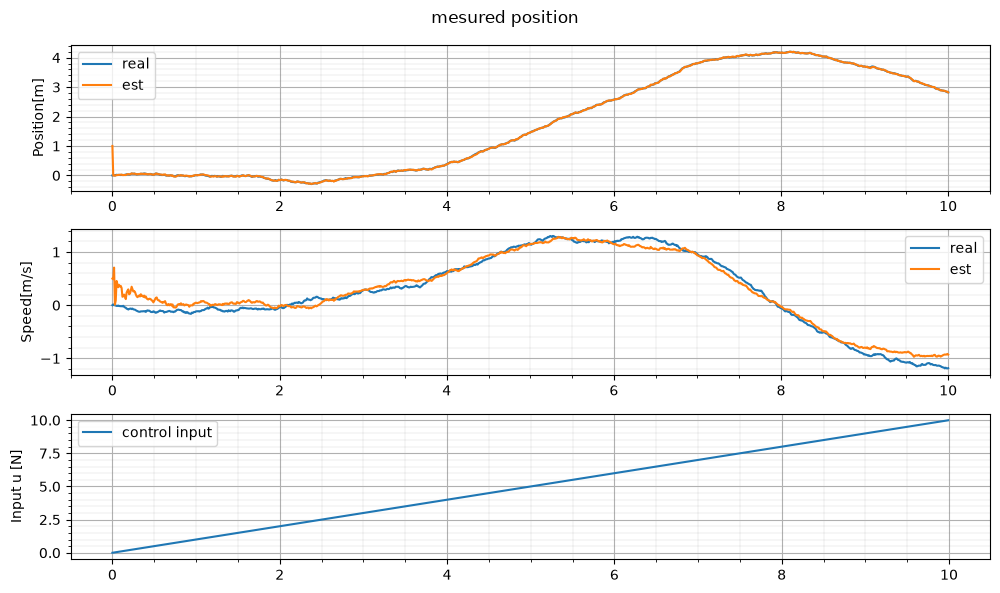

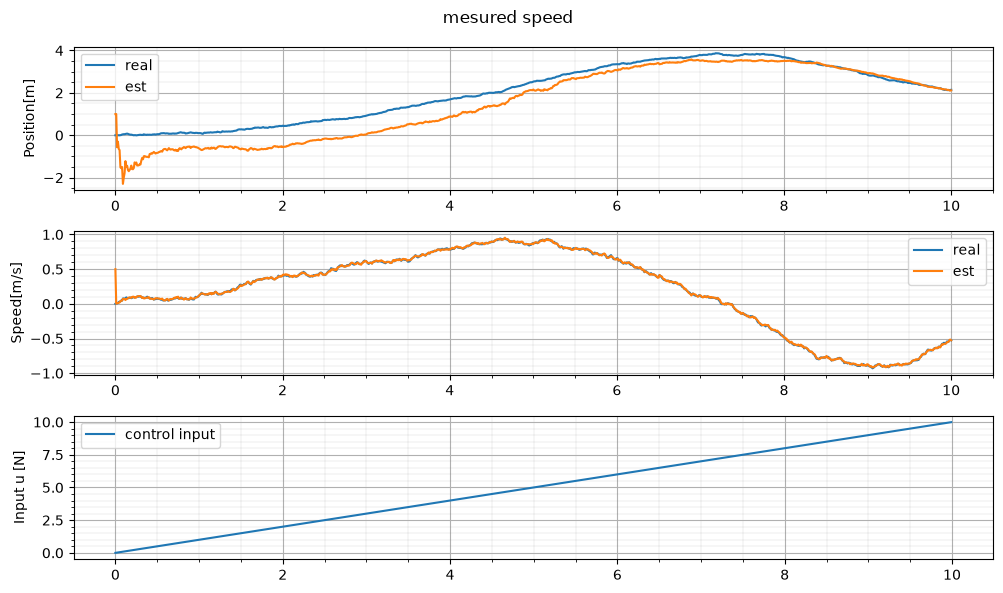

In [10]:
dt = 1e-2 # [s]
duration = 10 #[s]
sampling_point = int(duration/dt)
time_window = np.arange(sampling_point) * dt
u_array = time_window* 1

X_init = np.array([0,0])
X_est_init = np.array([1.0,0.5])

params = Parameters(
    dt=dt,
    k=1.0,
    c=0.1,
    Q=np.diag([1e-4,1e-4]),
    R=np.array([[1e-4]]),
    P_init=np.diag([1e1, 1e1])
)

t_array, x_array_x, x_est_array_x = simulation(X_init, X_est_init, u_array, params)
create_fig(t_array, x_array_x, x_est_array_x, u_array, title="mesured position")

t_array, x_array_v, x_est_array_v = simulation(X_init, X_est_init, u_array, params, measure_speed=True)
create_fig(t_array, x_array_v, x_est_array_v, u_array, title="mesured speed")

位置を観測値とした場合、位置の推定値は真値に近く、速度の推定値は真値からズレがある。

速度を観測値とした場合、位置の推定値は真値からズレがあり、速度の推定値は真値に近い。

推定値のRMSEを比較すると次のようになる。

In [11]:
n = len(t_array)

rmse_x = 0
for x_est, x in zip(x_est_array_x, x_array_x):
    rmse_x += (x_est - x)**2

rmse_x=np.sqrt(rmse_x / n)

rmse_v = 0
for x_est, x in zip(x_est_array_v, x_array_v):
    rmse_v += (x_est - x)**2

rmse_v=np.sqrt(rmse_v / n)

print(f"観測値XのRMSE , X: {rmse_x[0]:05F} , V: {rmse_x[1]:05F}")
print(f"観測値VのRMSE , X: {rmse_v[0]:05F} , V: {rmse_v[1]:05F}")


観測値XのRMSE , X: 0.032650 , V: 0.121587
観測値VのRMSE , X: 0.641587 , V: 0.017722


それぞれのRMMSは観測できる状態と観測できない推定状態では約10倍の差が生じるという結果となった。

## 2. 外乱推定

1.状態推定では外乱$d$をゼロとして扱った。この節では、外乱を状態へ組み込み拡張状態$X$を推定する。

$$
X = \begin{bmatrix}
x \\ v \\ d
\end{bmatrix}
$$

### 2.1. 外乱を含む拡張状態方程式

外乱が一定、またはその変化が緩やかであると仮定する。

簡単なモデルとして、以下と採用する。

$$
\dot{d} = 0
$$

すると、拡張状態方程式は以下となる。

$$
\begin{bmatrix}
\dot{x} \\ \dot{v} \\ \dot{d}
\end{bmatrix} =
\begin{bmatrix}
v \\
\frac{1}{m}(u - cv - k x|x| + d) \\
0
\end{bmatrix}
$$

これは外乱が完全に一定という意味ではなく、次の時刻まで変化しないと仮定しているモデルである。

### 2.2. 離散時間状態方程式

$$
\begin{array}{c}
X_{n+1} = f(X_n, u_n) + w_n \\
\downarrow \\
\begin{bmatrix}
x_{n+1} \\ v_{n+1} \\ d_{n+1}
\end{bmatrix} =
\begin{bmatrix}
x_n + \Delta t v_n \\
v_n + \frac{\Delta t}{m}(u_n - cv_n - k x_n|x_n| + d_n) \\
d_n
\end{bmatrix} + w_n
\end{array}
$$

ここで$w_k$は外乱の変化量を含むプロセスノイズであり、以下である。

$$
w_n \sim \mathcal{N}(0, Q_n)
$$

プロセスノイズ共分散$Q_n$は3次元となる。

$$
Q_n = \begin{bmatrix}
q_x & 0 & 0 \\
0 & q_v & 0 \\
0 & 0 & q_d
\end{bmatrix}
$$

$q_d$は値の大小により以下のような意味となる。

- $q_d = 0$ : 外乱が一定というモデル。ただし、状態間の相関によって外乱推定値が更新される場合がある。
- $q_d$が小さい : 外乱はゆっくり変化すると仮定する。
- $q_d$が大きい : 外乱は比較的速く変化すると仮定する。

### 2.3. 観測方程式

状態が3次元へ拡張されている。そのため、位置を観測値とする場合、次の観測方程式となる。

$$
z_n = h(X_n) + r_n = \begin{bmatrix}1 & 0 & 0 \end{bmatrix}X_n + r_n
$$

### 2.4 UKFの1ループ

状態へ外乱が追加されて3次元ととなっていること以外は処理内容に変化はない。以下では各変数の次元のみを示す。

- 状態数 $n=3$
- 推定状態 $\hat{x}_{k|k} \in \mathcal{R}^{3 \times 1}$
- 誤差共分散行列 $P_{k|k} \in \mathcal{R}^{3 \times 3}$
- シグマポイント $\chi_{k|k} \in \mathcal{R}^{3 \times 1}$
- シグマポイント $\psi_{k+1|k} \in \mathcal{R}^{3 \times 1}$
- シグマポイント $Z_{k+1} \in \mathcal{R}^{1 \times 1}$
- 観測値の予測値 $\hat{z}_{k+1|k} \in \mathcal{R}^{1 \times 1}$
- 観測値の予測誤差共分散 $S_{k+1} \in \mathcal{R}^{1 \times 1}$
- 交差共分散 $P_{xz} \in \mathcal{R}^{3 \times 1}$
- Kalman Gain $K \in \mathcal{R}^{3 \times 1}$

### Python Code

In [12]:
@dataclass
class Parameters:

    dt:float  = 1e-3 # Simulation Step

    m:float = 10 # 慣性 [kg]
    c:float = 0.1 # 粘性 [N s/m]
    k:float = 1.4 # 剛性 [N/m^2]

    # 状態数
    nx : int = 3

    # 観測数
    nz : int = 1

    # 誤差共分散行列の初期値
    P_init : np.ndarray = field(
        default_factory=lambda: np.diag([1e1, 1e1, 1e1]), compare=False
    )

    Q_real: np.ndarray = field(
        default_factory=lambda:np.diag([1e-3, 1e-3]), compare=False
    )

    # プロセスノイズの分散Q
    Q: np.ndarray = field(
        default_factory=lambda: np.diag([1e-3, 1e-3, 1e1]), compare=False
    )

    # 観測ノイズの分散R
    R: np.ndarray = field(
        default_factory=lambda: np.array([[1e-2]]), compare=False
    )

    alpha:float  = 1.0
    beta:float = 2.0
    kappa:float = 0.0

def real_system(X_n:np.ndarray, u_n:float, d_n:float, params:Parameters):
    x_n, v_n = X_n
    x_next = x_n + params.dt * v_n
    v_next = v_n + params.dt/params.m*(u_n - params.c * v_n - params.k * x_n * np.abs(x_n) + d_n)
    return np.array([x_next, v_next])

def fake_real_system(X_n:np.ndarray, u_n:float, params:Parameters):
    x_n, v_n, d_n = X_n
    x_next = x_n + params.dt * v_n
    v_next = v_n + params.dt/params.m*(u_n - params.c * v_n - params.k * x_n * np.abs(x_n) + d_n)
    d_next = d_n
    return np.array([x_next,v_next, d_next])

def mesurement_value(X_n:np.ndarray, mesure_speed:bool=False):
    x_n, v_n = X_n
    if mesure_speed:
        return np.array([v_n])
    else:
        return np.array([x_n])

def fake_mesurement_value(X_n:np.ndarray, mesure_speed:bool=False):
    x_n, v_n , _ = X_n
    if mesure_speed:
        return np.array([v_n])
    else:
        return np.array([x_n])


In [13]:
def calculate_UKF_one_loop(hat_x:np.ndarray, P:np.ndarray, u:float, z:float, params:Parameters, measure_speed=False):

    # シグマポイントを計算
    sigmas = generate_sigma_points(hat_x, P, params)
    # 重みの計算
    w_m , w_c = genrate_weights(params)

    # シグマポイントを状態方程式に通過させる
    chis = np.array([fake_real_system(s, u, params) for s in sigmas])

    # 事前推定値の状態を計算
    x_pred = np.sum(w_m[:, None] * chis, axis=0)

    # 事前推定値の分散を計算
    P_pred = params.Q.copy()
    for i in range(len(w_m)):
        diff = chis[i] - x_pred
        P_pred += w_c[i] * np.outer(diff, diff)

    # シグマポイントを計算
    psi = generate_sigma_points(x_pred, P_pred, params)

    # シグマポイントを観測方程式に通過させる
    Z = np.array([fake_mesurement_value(s, measure_speed) for s in psi])

    # 予測観測値を求める
    z_pred = np.sum(w_m[:, None]* Z, axis=0)

    # 観測値の予測誤差共分散を求める
    S_pred = params.R.copy()
    for i in range(len(w_m)):
        diff = Z[i] - z_pred
        S_pred += w_c[i] * np.outer(diff, diff)

    # 交差共分散を求める
    Pxz = np.zeros((params.nx, params.nz))
    for i in range(len(w_m)):
        diff_x = psi[i] - x_pred
        diff_z = Z[i] - z_pred
        Pxz += w_c[i] * np.outer(diff_x, diff_z)

    # カルマンゲインの計算
    K = np.linalg.solve(S_pred, Pxz.T).T

    # innovation
    tilde_z = z - z_pred

    # 事後推定 状態
    x_est = x_pred + K @ tilde_z

    # 事後推定 共分散行列
    P_est = P_pred - K @ S_pred @ K.T
    P_est = 0.5*(P_est + P_est.T)
    return x_est, P_est



In [14]:
def simulation(X_init: np.ndarray,X_est_init:np.ndarray, u_array:np.ndarray, d_array:np.ndarray, params:Parameters, measure_speed=False):

    X_history = []
    X_est_history = []
    time_array = []

    X_history.append(X_init)
    X_est_history.append(X_est_init)
    time_array.append(0)
    P_est = params.P_init
    n = len(u_array)

    for i in range(n):
        w_real = (
            np.random.multivariate_normal(mean=np.zeros(2), cov=params.Q_real)
        )

        # システムの状態
        X_for_sim = X_history[i].copy()
        X_real = real_system(X_for_sim, u_array[i], d_array[i],params) + w_real # 外乱は状態に含まれるので、ここで加算しない

        # システムの観測値
        z = mesurement_value(X_real, measure_speed) + fake_mesurement_noiz(params)

        # UFKによる状態推定
        X_est, P_est = calculate_UKF_one_loop(X_est_history[i], 
                                              P_est, 
                                              u_array[i], 
                                              z, 
                                              params,
                                              measure_speed)

        X_est_history.append(X_est)
        X_history.append(X_real)

        time_array.append(params.dt * (i+1))

    return np.asarray(time_array), np.asarray(X_history), np.asarray(X_est_history)


In [15]:
def create_fig(t_array, x_array, x_est_array, u_array, d_array, title=""):

    fig, ax = plt.subplots(4,1, figsize=(10,7))

    ax[0].set_ylabel("Position[m]")
    ax[0].plot(t_array, x_array[:,0], label="real")
    ax[0].plot(t_array, x_est_array[:,0], label="est")

    ax[1].set_ylabel("Speed[m/s]")
    ax[1].plot(t_array, x_array[:,1], label="real")
    ax[1].plot(t_array, x_est_array[:,1], label="est")

    ax[2].set_ylabel("disturbance[N]")
    ax[2].plot(t_array[:len(d_array)], d_array , label="real")
    ax[2].plot(t_array, x_est_array[:,2], label="est")

    ax[3].set_ylabel("Input u [N]")
    ax[3].plot(t_array[:len(u_array)], u_array, label="control input")

    for i in range(4):
        ax[i].grid()
        ax[i].grid(which='minor', lw=0.1, color='grey')
        ax[i].minorticks_on()

        ax[i].legend()

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

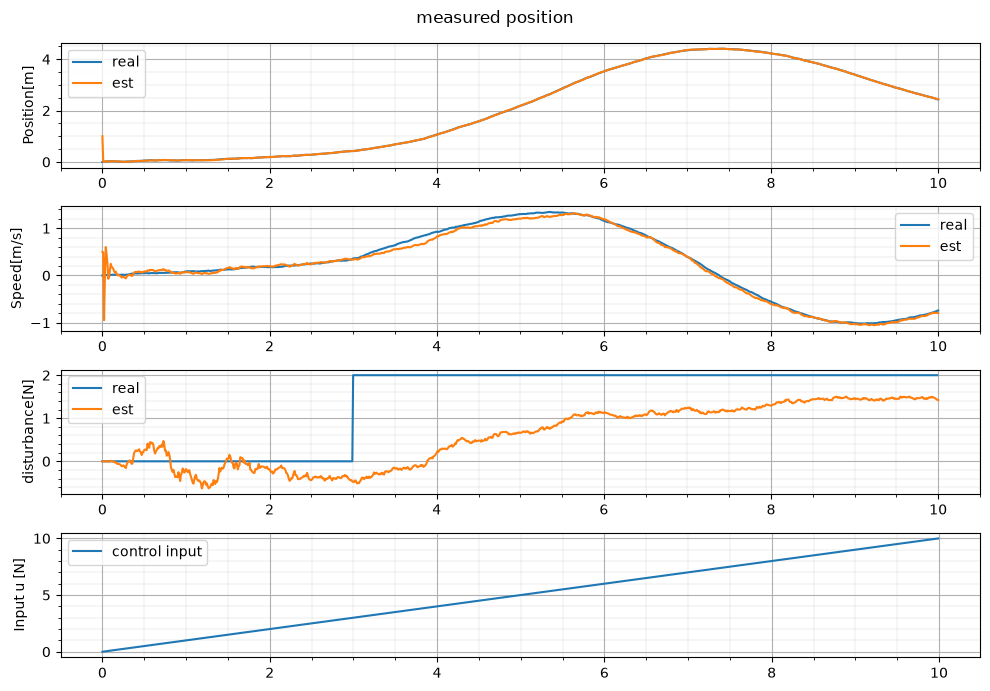

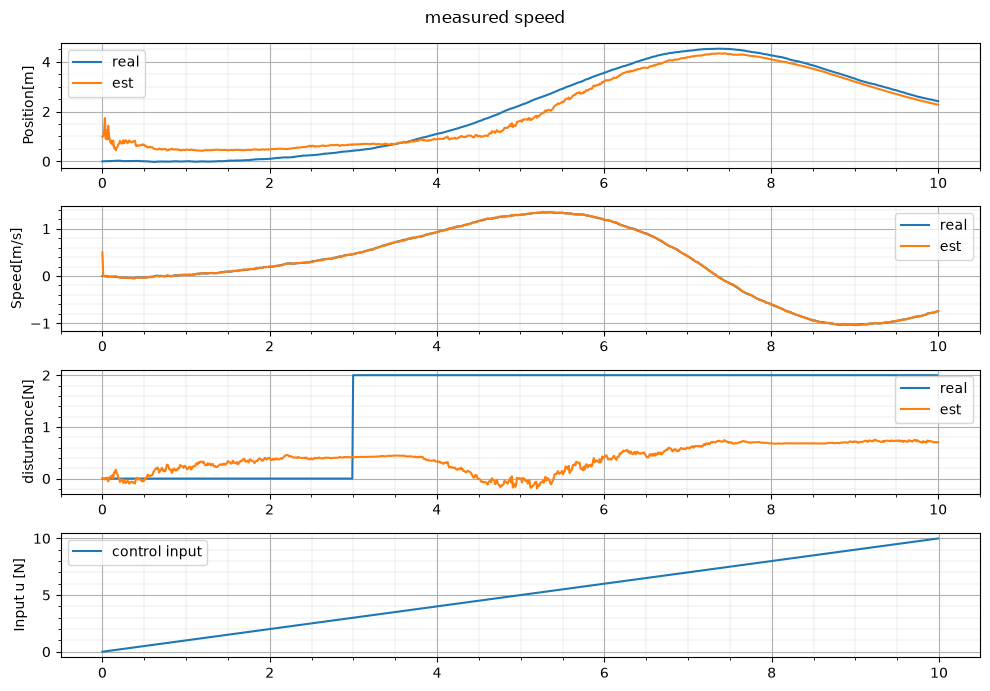

In [16]:
np.random.seed(0)
dt = 1e-2 # [s]
duration = 10 #[s]
sampling_point = int(duration/dt)
time_window = np.arange(sampling_point) * dt
u_array = time_window* 1
d_array = []
for t in time_window:
    if t < 3:
        d_array.append(0)
    else:
        d_array.append(2)
d_array = np.asarray(d_array)

X_init = np.array([0,0])
X_est_init = np.array([1.0,0.5,0.0])

params = Parameters(
    dt=dt,
    k=1.0,
    c=0.1,
    Q=np.diag([1e-5,4e-5, 2e-4]),
    Q_real=np.diag([1e-5, 1e-5]),
    R=np.array([[1e-4]]),
    P_init=np.diag([1e1, 1e1, 1e0])
)

t_array, x_array, x_est_array = simulation(X_init,X_est_init,u_array, d_array, params, measure_speed=False)
create_fig(t_array, x_array, x_est_array, u_array, d_array, title="measured position")

t_array, x_array, x_est_array = simulation(X_init,X_est_init,u_array, d_array, params, measure_speed=True)
create_fig(t_array, x_array, x_est_array, u_array, d_array, title="measured speed")

外乱$d$の変化は2Nとしている。

これに対し、速度$v_{n+1}$に対するプロセスノイズ$w_{v,n}$で影響する。

$$
v_{n+1} = v_n + \frac{\Delta t}{m}(u_n - c v_n - k x_n |x_n| +d_n) + w_{v,n}
$$

実際の`real_system`での計算では平均ゼロの正規分布で計算しているが、外乱$d$とプロセスノイズ$w_{v,n}$が$v_{n+1}$に与える影響はそれぞれの次のように見積もることが出来る.

- 外乱による速度変化
    $$
    \Delta v_d = \Delta t / m \times d = 0.01 / 10 \times 2 = 0.002 \text{ m/s}
    $$

- プロセスノイズ(1 シグマ)
    $$
    \sigma_{w_v} = \sqrt{10^{-5}} \approx 0.00316  \text{ m/s}
    $$

よって、外乱による1ステップの速度変化よりも、速度のプロセスノイズの標準偏差が大きい。そのため、短時間の観測からの外乱の影響を識別することが難しくなり、外乱推定の収束速度や精度が低下する可能性がある。

次にプロセスノイズを外乱による速度変化の一桁下の値として計算すると以下の値となる。これをプロセスノイズ$w_v$に与えて計算を行う。

$$
\sqrt{q_v} = 0.0002 \rightarrow q_v = 4 \times 10^{-8}
$$

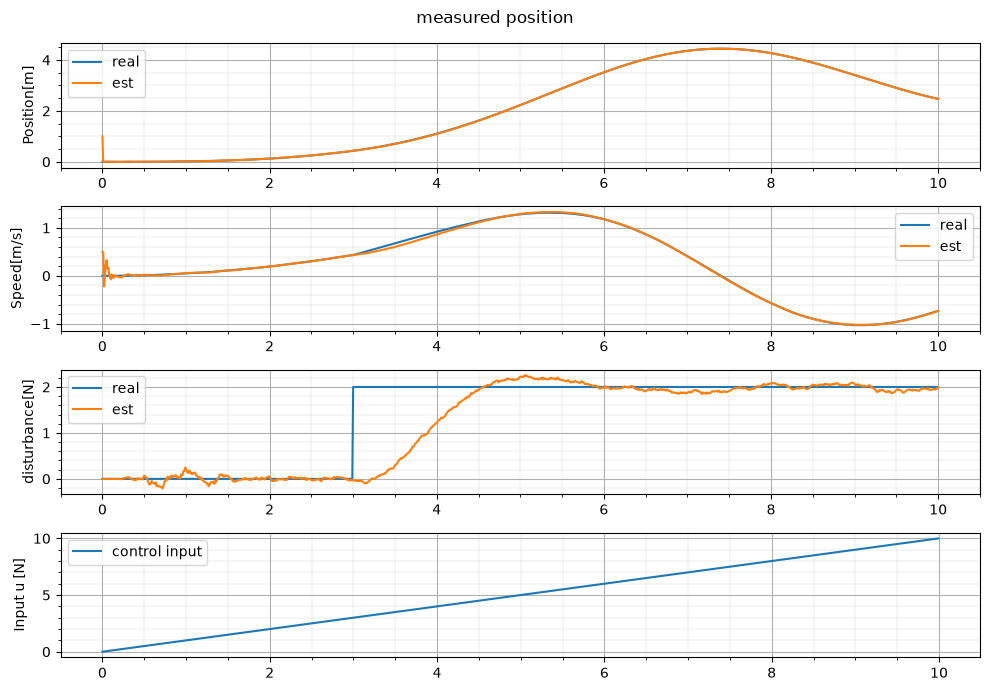

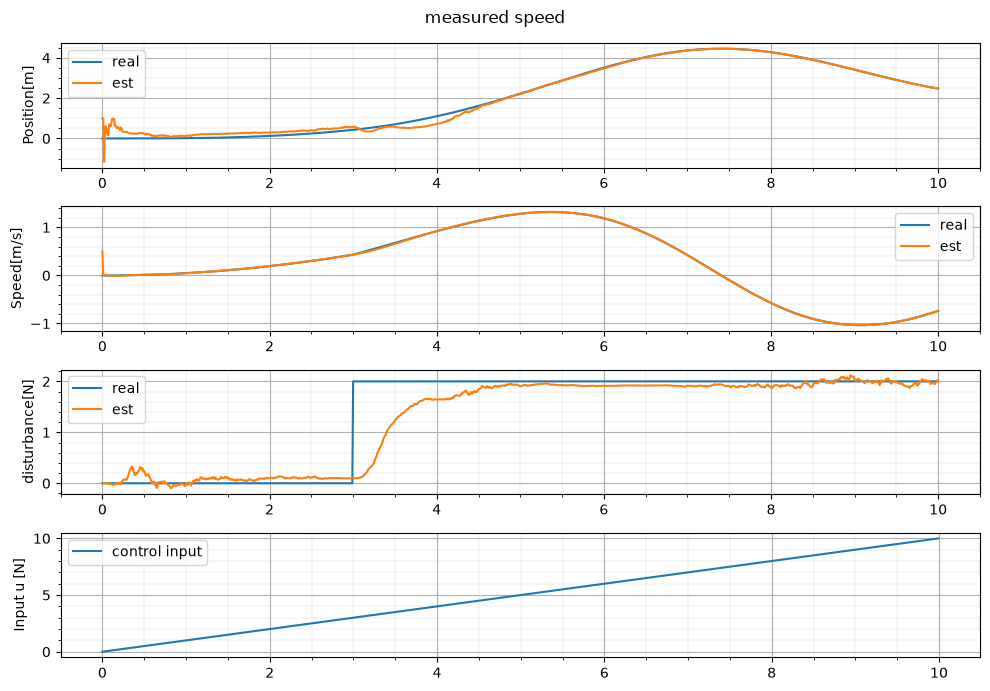

In [17]:
params = Parameters(
    dt=dt,
    k=1.0,
    c=0.1,
    Q=np.diag([0,0, 2e-4]), # for UKF
    Q_real=np.diag([1e-8, 4e-8]), # for real
    R=np.array([[1e-4]]),
    P_init=np.diag([1e1, 1e1, 1e-1])
)

t_array, x_array, x_est_array = simulation(X_init,X_est_init,u_array, d_array, params, measure_speed=False)
create_fig(t_array, x_array, x_est_array, u_array, d_array, title="measured position")

t_array, x_array, x_est_array = simulation(X_init,X_est_init,u_array, d_array, params, measure_speed=True)
create_fig(t_array, x_array, x_est_array, u_array, d_array, title="measured speed")

UKFで設定する状態$x,v$に対するプロセスノイズをゼロとして、`real_system`のノイズを$ \times 10^{-8}$と設定下場合、プロセスノイズが小さくなったことで、外乱の推定がうまくできるようになった。

次は、UKFで設定する状態$x,v$に対するプロセスノイズに値を設定した場合の実験を行う。

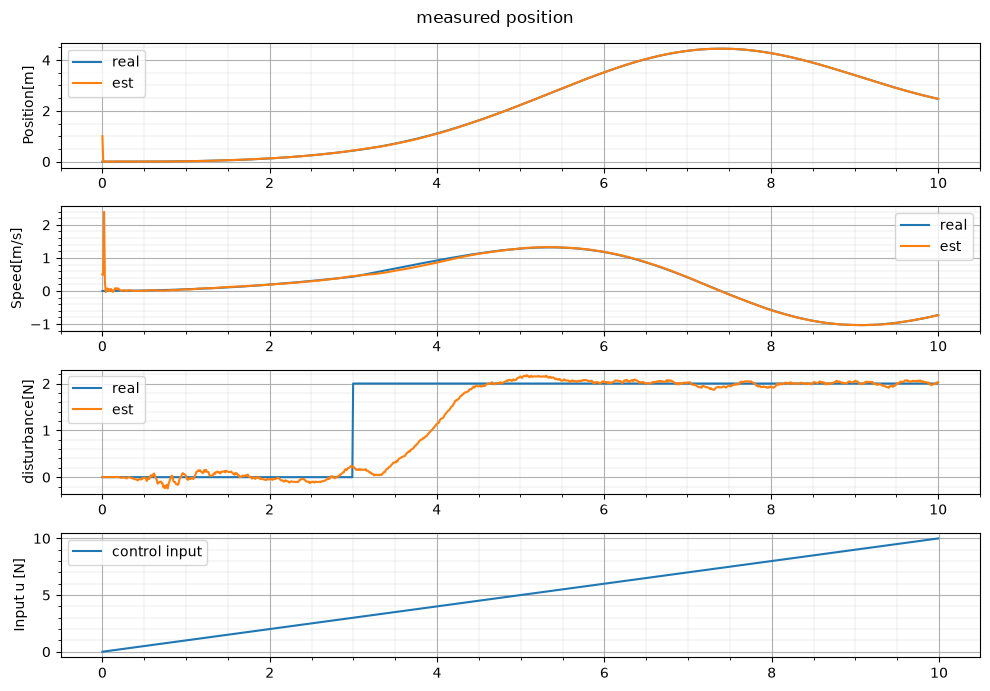

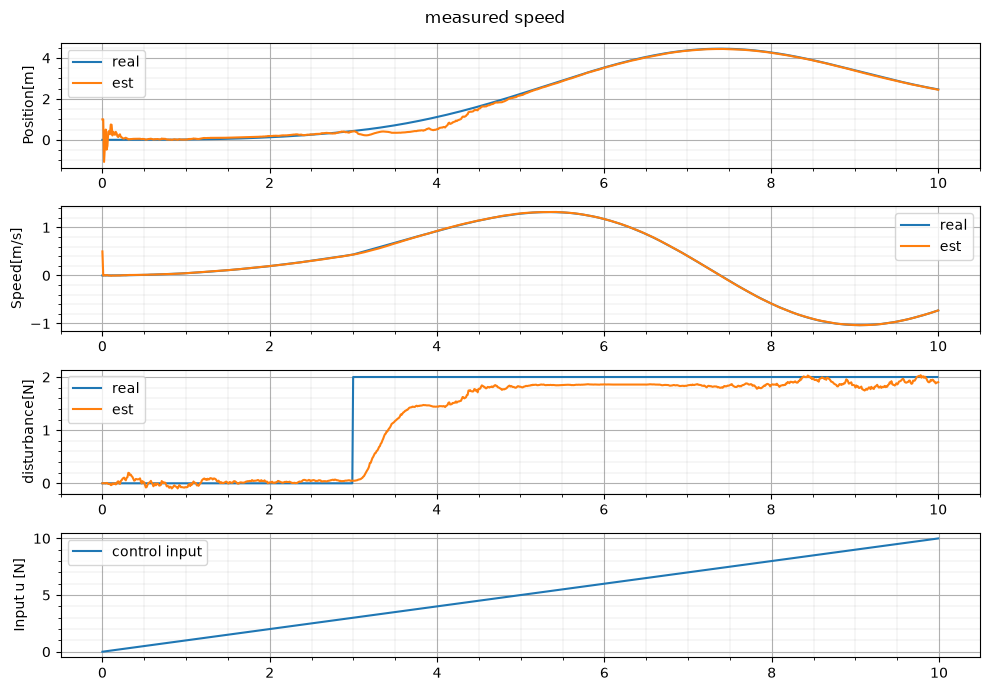

In [18]:
params = Parameters(
    dt=dt,
    k=1.0,
    c=0.1,
    Q=np.diag([1e-8, 4e-8, 2e-4]), # for UKF
    Q_real=np.diag([1e-8, 4e-8]), # for real
    R=np.array([[1e-4]]),
    P_init=np.diag([1e1, 1e1, 1e-1])
)

t_array, x_array, x_est_array = simulation(X_init,X_est_init,u_array, d_array, params, measure_speed=False)
create_fig(t_array, x_array, x_est_array, u_array, d_array, title="measured position")

t_array, x_array, x_est_array = simulation(X_init,X_est_init,u_array, d_array, params, measure_speed=True)
create_fig(t_array, x_array, x_est_array, u_array, d_array, title="measured speed")

UKFのプロセスノイズは`real_system`の大きさと一致させている。

この結果ではUKFのプロセスノイズがゼロの状態とほぼ一致している。

これより、

- 実システムで生じているプロセスノイズの大きさと同等以下の外乱が生じる場合、その外乱推定の収束速度や精度が低下する

といえる。

## 3. パラメータ推定

#### 3.1. 設定

モデルを再掲する。

$$
m \ddot{x} + c \dot{x} + k x|x| = u + d
$$

重量$m$は計測しやすいため、未知パラメータを$c,k$とする。

そして、観測する状態は位置と速度の両方を観測できるとする。また、外乱$d$はゼロとして扱う。

#### 3.2 拡張状態方程式

推定する未知パラメータである$c,k$を状態に追加し、以下の拡張状態を定義する。

$$
X_n = \begin{bmatrix}
x_n \\ v_n \\ c_n \\ k_n
\end{bmatrix}
$$

$c,k$は基本的に一定値だが、UKFではランダムウォークとして扱う。

$$
\begin{aligned}
c_{n+1} &= c_{n} + w_{c,n} \\
k_{k+1} &= k_{n} + w_{k,n} \\
\end{aligned}
$$

これより、離散時間状態方程式は以下となる。

$$
X_{n+1} = \begin{bmatrix}
x_{n} + \Delta t v_n \\
v_n + \frac{\Delta t}{m}(u_n - c_n v_n - k_n x_n|x_n| + d_n) \\
c_n \\
k_n
\end{bmatrix} + w_n
$$

$w_n$は$\mathcal{N}(0, Q_n)$に従う。$Q_n$は$x,v$へのプロセスノイズに$c,k$のランダムウォークの大きさを示す項$q_c,q_k$を加えた以下の共分散行列である。

$$
Q_n = \begin{bmatrix}
q_x & 0 & 0 & 0 \\
0 & q_v & 0 & 0 \\
0 & 0 & q_c & 0 \\
0 & 0 & 0 & q_k \\
\end{bmatrix}
$$

今回は$x,v$の両方を計測できるとし、観測方程式は以下となる。

$$
z_{n} = \begin{bmatrix}
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 
\end{bmatrix}
\begin{bmatrix}
x_n & v_n & c_n & k_n 
\end{bmatrix} + r_n
$$

$r_n$は$\mathcal{N}(0, R_n)$に従う。$R_n$は$x_n, v_n$観測時に加わるノイズの大きさを示す。

$$
R = \begin{bmatrix}
\sigma_{x}^2 & 0 \\
0 & \sigma_{v}^2
\end{bmatrix}
$$






### 3.3. パラメータを推定できる条件

運動方程式を変形すると以下となる。

$$
u - m \ddot{x} = c v + k x|x|
$$

仮にシステムの運動が以下の線形関係である場合、

$$
v = a x|x|
$$

以下のようになり、$(ac+k)$として認識できるが、$c$と$k$を分離して認識することはできない。

$$
u - m \ddot{x} = (ac + k) x|x|
$$

よって、ランプ入力、または正弦波入力を使用する。

### 3.4. UKFの1ループ

状態へパラメータ$c,k$が追加され4次元となること、観測状態が2次元となること以外はUKFの計算内容に変更はない。以下では各変数の次元のみを示す。

- 状態数 $nx=4$
- 観測数 $nz=2$
- 推定状態 $\hat{x}_{k|k} \in \mathcal{R}^{4 \times 1}$
- 誤差共分散行列 $P_{k|k} \in \mathcal{R}^{4 \times 4}$
- シグマポイント $\chi_{k|k} \in \mathcal{R}^{4 \times 1}$
- シグマポイント $\psi_{k+1|k} \in \mathcal{R}^{4 \times 1}$
- シグマポイント $Z_{k+1} \in \mathcal{R}^{2 \times 1}$
- 観測値の予測値 $\hat{z}_{k+1|k} \in \mathcal{R}^{2 \times 1}$
- 観測値の予測誤差共分散 $S_{k+1} \in \mathcal{R}^{2 \times 2}$
- 交差共分散 $P_{xz} \in \mathcal{R}^{4 \times 2}$
- Kalman Gain $K \in \mathcal{R}^{4 \times 2}$

In [19]:
@dataclass
class Parameters:

    dt:float  = 1e-3 # Simulation Step

    m:float = 10 # 慣性 [kg]
    c:float = 0.1 # 粘性 [N s/m]
    k:float = 1.4 # 剛性 [N/m^2]

    # 状態数
    nx : int = 4

    # 観測数
    nz : int = 2

    # 誤差共分散行列の初期値
    P_init : np.ndarray = field(
        default_factory=lambda: np.diag([1e2, 1e2]), compare=False
    )

    # 実機のプロセスノイズの分散Q
    Q_real: np.ndarray = field(
        default_factory=lambda: np.diag([1e-3, 1e-3]), compare=False
    )


    # プロセスノイズの分散Q
    Q: np.ndarray = field(
        default_factory=lambda: np.diag([1e-5, 1e-5, 1e-4, 1e-4]), compare=False
    )

    # 観測ノイズの分散R
    R: np.ndarray = field(
        default_factory=lambda: np.diag([[1e-3, 1e-3]]), compare=False
    )

    alpha:float  = 1.0
    beta:float = 2.0
    kappa:float = 0.0

def real_system(X_n:np.ndarray, u_n:float, params:Parameters):
    x_n, v_n = X_n
    x_next = x_n + params.dt * v_n
    v_next = v_n + params.dt/params.m*(u_n - params.c * v_n - params.k * x_n * np.abs(x_n))
    return np.array([x_next,v_next])

def fake_real_system(X_n:np.ndarray, u_n:float, params:Parameters):
    x_n, v_n, c_n, k_n = X_n
    x_next = x_n + params.dt * v_n
    v_next = v_n + params.dt/params.m*(u_n - c_n * v_n - k_n * x_n * np.abs(x_n))
    c_next = c_n
    k_next = k_n
    return np.array([x_next,v_next, c_next, k_next])

def mesure_value(X_n:np.ndarray):
    return X_n

def fake_mesurement_value(X_n:np.ndarray):
    x_n, v_n, _, _ = X_n
    return np.array([x_n, v_n])

def process_noize(params:Parameters):
    return np.random.multivariate_normal(mean=np.zeros(2), cov=params.Q_real)

def mesurement_noiz(params:Parameters):
    return np.random.multivariate_normal(mean=np.zeros(2), cov=params.R)

def generate_sigma_points(x_mean:np.ndarray, P:np.ndarray, params:Parameters):
    n = params.nx
    lam = params.alpha**2*(n + params.kappa) - n
    U = np.linalg.cholesky((n + lam) * P)

    # シグマポイントの計算
    sigmas = np.zeros((2*n + 1, n))
    sigmas[0] = x_mean
    for i in range(n):
        sigmas[i+1] = x_mean + U[:,i]
        sigmas[n+i+1] = x_mean - U[:,i]

    return sigmas

def genrate_weights(params:Parameters):
    n = params.nx
    lam = params.alpha**2*(n + params.kappa) - n
    # 重み計算
    weights_mean = np.zeros(2*n + 1)
    weights_cov = np.zeros(2*n + 1)

    weights_mean[0] = lam / (n+lam)
    weights_cov[0] = weights_mean[0] + (1 - params.alpha**2 + params.beta)

    for i in range(1, 2*n+1):
        weights_mean[i] = 1.0 / (2*(n + lam))
        weights_cov[i] = weights_mean[i]

    return weights_mean, weights_cov

In [20]:
def calculate_UKF_one_loop(hat_x:np.ndarray, P:np.ndarray, u:float, z:float, params:Parameters):

    # シグマポイントを計算
    sigmas = generate_sigma_points(hat_x, P, params)
    # 重みの計算
    w_m , w_c = genrate_weights(params)

    # シグマポイントを状態方程式に通過させる
    chis = np.array([fake_real_system(s, u, params) for s in sigmas])

    # 事前推定値の状態を計算
    x_pred = np.sum(w_m[:, None] * chis, axis=0)

    # 事前推定値の分散を計算
    P_pred = params.Q.copy()
    for i in range(len(w_m)):
        diff = chis[i] - x_pred
        P_pred += w_c[i] * np.outer(diff, diff)

    # シグマポイントを計算
    psi = generate_sigma_points(x_pred, P_pred, params)

    # シグマポイントを観測方程式に通過させる
    Z = np.array([fake_mesurement_value(s) for s in psi])

    # 予測観測値を求める
    z_pred = np.sum(w_m[:, None]* Z, axis=0)

    # 観測値の予測誤差共分散を求める
    S_pred = params.R.copy()
    for i in range(len(w_m)):
        diff = Z[i] - z_pred
        S_pred += w_c[i] * np.outer(diff, diff)

    # 交差共分散を求める
    Pxz = np.zeros((params.nx, params.nz))
    for i in range(len(w_m)):
        diff_x = psi[i] - x_pred
        diff_z = Z[i] - z_pred
        Pxz += w_c[i] * np.outer(diff_x, diff_z)

    # カルマンゲインの計算
    K = np.linalg.solve(S_pred, Pxz.T).T

    # innovation
    tilde_z = z - z_pred

    # 事後推定 状態
    x_est = x_pred + K @ tilde_z

    # 事後推定 共分散行列
    P_est = P_pred - K @ S_pred @ K.T
    P_est = 0.5*(P_est + P_est.T)
    return x_est, P_est



In [21]:
def simulation(X_init: np.ndarray,X_est_init:np.ndarray, u_array:np.ndarray, params:Parameters):

    X_history = []
    X_est_history = []
    time_array = []

    X_history.append(X_init)
    X_est_history.append(X_est_init)
    time_array.append(0)
    P_est = params.P_init
    n = len(u_array)

    for i in range(n):
        w_real = process_noize(params)

        # システムの状態
        X_for_sim = X_history[i].copy()
        X_real = real_system(X_for_sim, u_array[i],params) + w_real

        # システムの観測値
        z = mesurement_value(X_real) + mesurement_noiz(params)

        # UFKによる状態推定
        X_est, P_est = calculate_UKF_one_loop(X_est_history[i], 
                                              P_est, 
                                              u_array[i], 
                                              z, 
                                              params,
                                              )

        X_est_history.append(X_est)
        X_history.append(X_real)

        time_array.append(params.dt * (i+1))

    return np.asarray(time_array), np.asarray(X_history), np.asarray(X_est_history)


In [26]:
def create_fig(t_array, x_array, x_est_array, u_array, params:Parameters, title=""):

    fig, ax = plt.subplots(5,1, figsize=(10,7.5))

    ax[0].set_ylabel("Position[m]")
    ax[0].plot(t_array, x_array[:,0], label="real")
    ax[0].plot(t_array, x_est_array[:,0], label="est")

    ax[1].set_ylabel("Speed[m/s]")
    ax[1].plot(t_array, x_array[:,1], label="real")
    ax[1].plot(t_array, x_est_array[:,1], label="est")

    ax[2].set_ylabel("viscosity[N s/m]")
    ax[2].axhline(params.c , color='red', linestyle="--", label="real")
    ax[2].plot(t_array, x_est_array[:,2], label="est")

    ax[3].set_ylabel("stifness [N/m]")
    ax[3].axhline(params.k , color='red', linestyle="--", label="real")
    ax[3].plot(t_array, x_est_array[:,3], label="est")

    ax[4].set_ylabel("Input u [N]")
    ax[4].plot(t_array[:len(u_array)], u_array, label="control input")

    for i in range(5):
        ax[i].grid()
        ax[i].grid(which='minor', lw=0.1, color='grey')
        ax[i].minorticks_on()

        ax[i].legend()

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

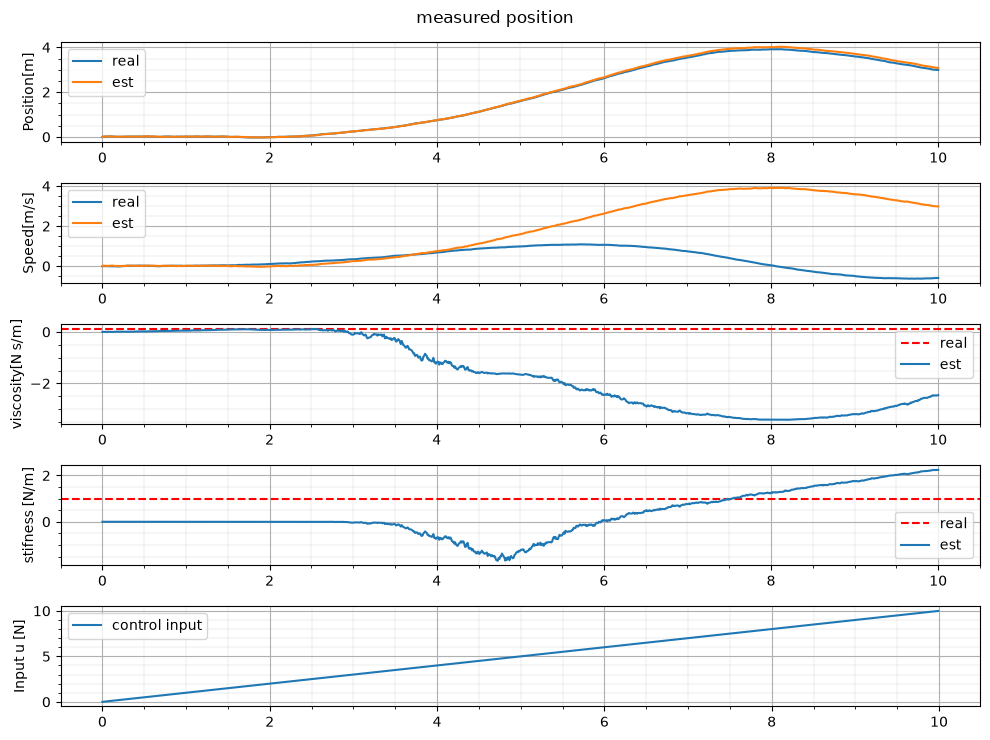

In [28]:
np.random.seed(0)
dt = 1e-2 # [s]
duration = 10 #[s]
sampling_point = int(duration/dt)
time_window = np.arange(sampling_point) * dt
u_array = time_window* 1

X_init = np.array([0,0])
X_est_init = np.array([0.0,0.0, 0.0, 0.0])

params = Parameters(
    dt=dt,
    k=1.0,
    c=0.1,
    Q=np.diag([1e-5,4e-5, 2e-4, 2e-4]),
    Q_real=np.diag([1e-5, 1e-5]),
    R=np.diag([1e-4, 1e-4]),
    P_init=np.diag([1e1, 1e1, 1e0, 1e0])
)

t_array, x_array, x_est_array = simulation(X_init,X_est_init,u_array,params)
create_fig(t_array, x_array, x_est_array, u_array, params, title="measured position")
